In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from pathlib import Path

In [8]:
def filename(thr1, thr2):
    return data_dir / f"Train_DivBS-RhoLos_thr-{thr1}-{thr2}_epoch-75.npy"

In [9]:
data_dir = Path("../interpolation/data")
thresholds = [
    0.0,
    0.1,
    0.2,
    0.4,
    0.6,
    0.8,
    1.0,
]


In [10]:
t = np.linspace(0, 1, 25)
curves = {}

for thr1, thr2 in combinations(thresholds, 2):
    path = filename(thr1, thr2)

    if not path.exists():
        raise FileNotFoundError(f"Could not find {path}")

    loss = np.load(path)

    if loss.shape != (25,):
        raise ValueError(
            f"{path} contains shape {loss.shape}, expected (25,)"
        )

    curves[(thr1, thr2)] = loss

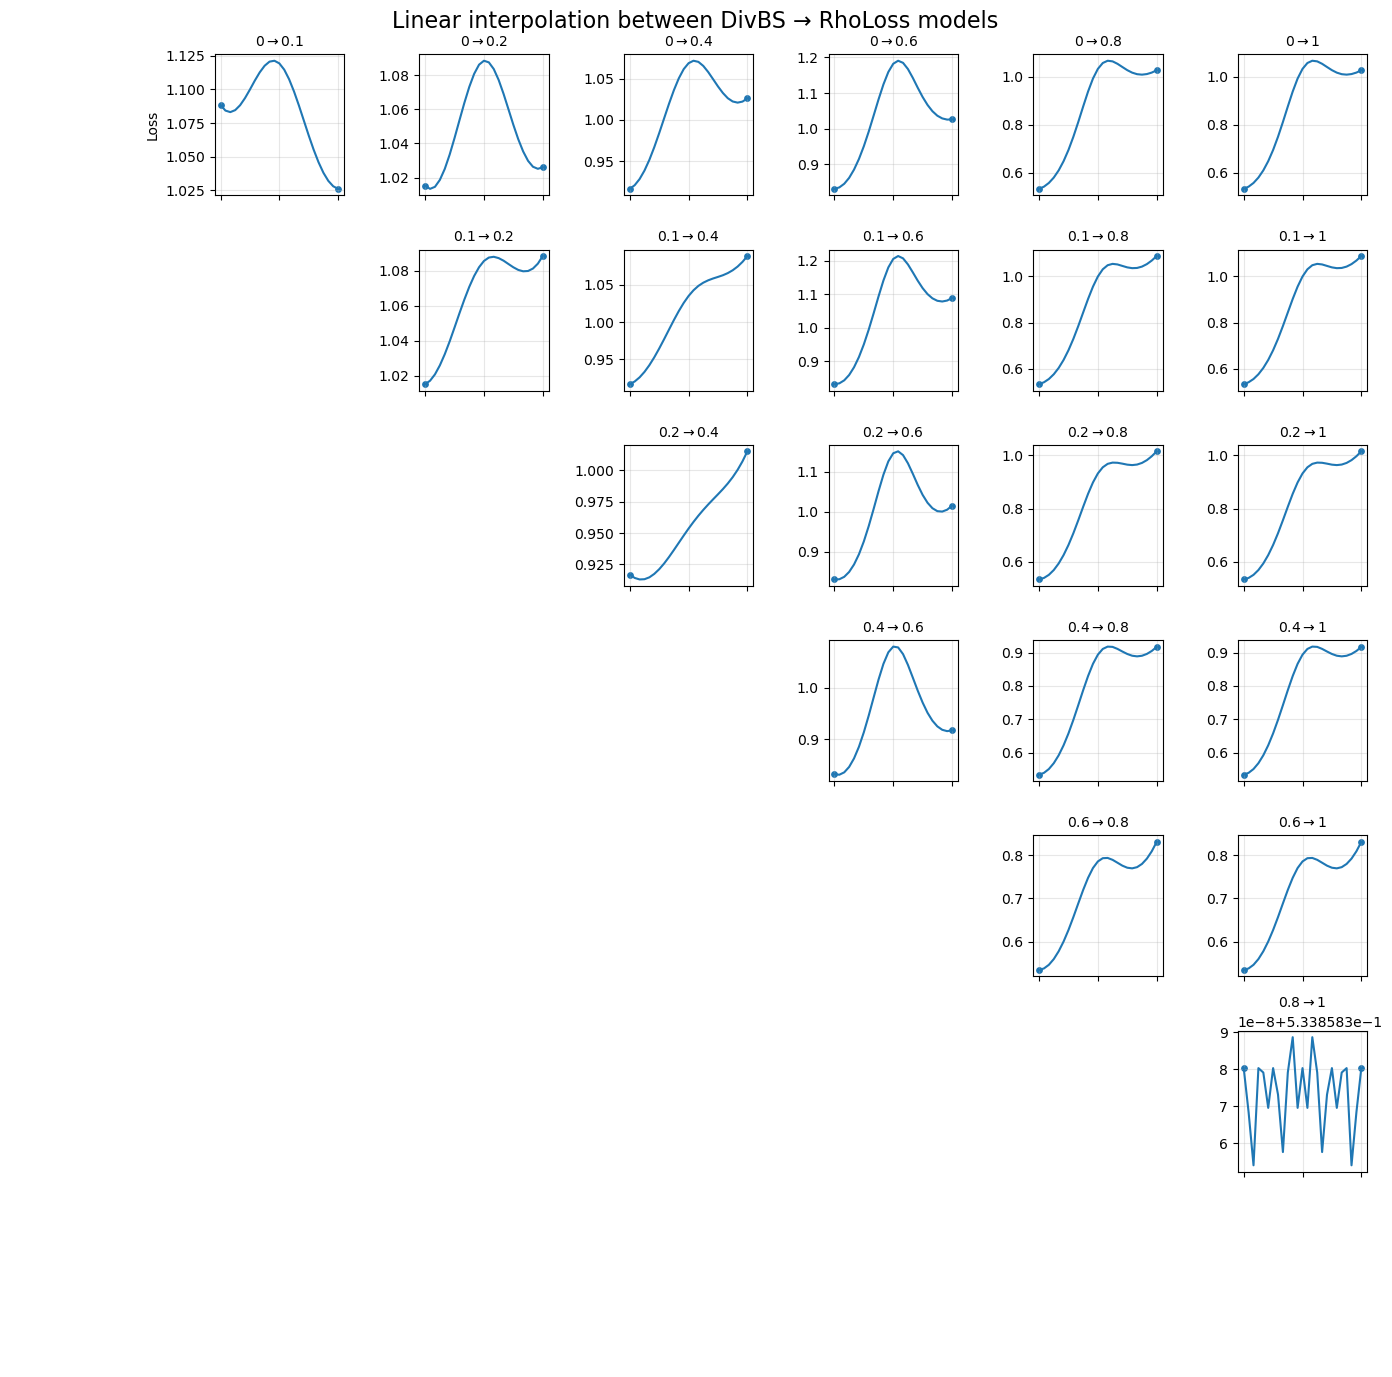

In [11]:
n = len(thresholds)
fig, axes = plt.subplots(
    n,
    n,
    figsize=(14, 14),
    sharex=True,
    sharey=False,
)

for i in range(n):
    for j in range(n):

        ax = axes[i, j]

        if i >= j:
            # Diagonal and lower triangle are unused
            ax.axis("off")
            continue

        thr1 = thresholds[i]
        thr2 = thresholds[j]

        loss = curves[(thr1, thr2)]

        ax.plot(t, loss)

        # Mark the two endpoints
        ax.scatter(
            [t[0], t[-1]],
            [loss[0], loss[-1]],
            s=15,
        )

        ax.set_title(
            rf"${thr1:g} \rightarrow {thr2:g}$",
            fontsize=10,
        )

        ax.grid(alpha=0.3)

        # Only put x labels on bottom row
        if i == n - 1:
            ax.set_xlabel(r"$t$")

        # Only put y labels on left side
        if j == 1:
            ax.set_ylabel("Loss")

fig.suptitle(
    "Linear interpolation between DivBS → RhoLoss models",
    fontsize=16,
)

fig.tight_layout()

plt.show()

In [12]:
fig
fig.savefig(
    "../interpolation/big_plots/train_interpolation_triangular.png",
    dpi=300,
    bbox_inches="tight",
)


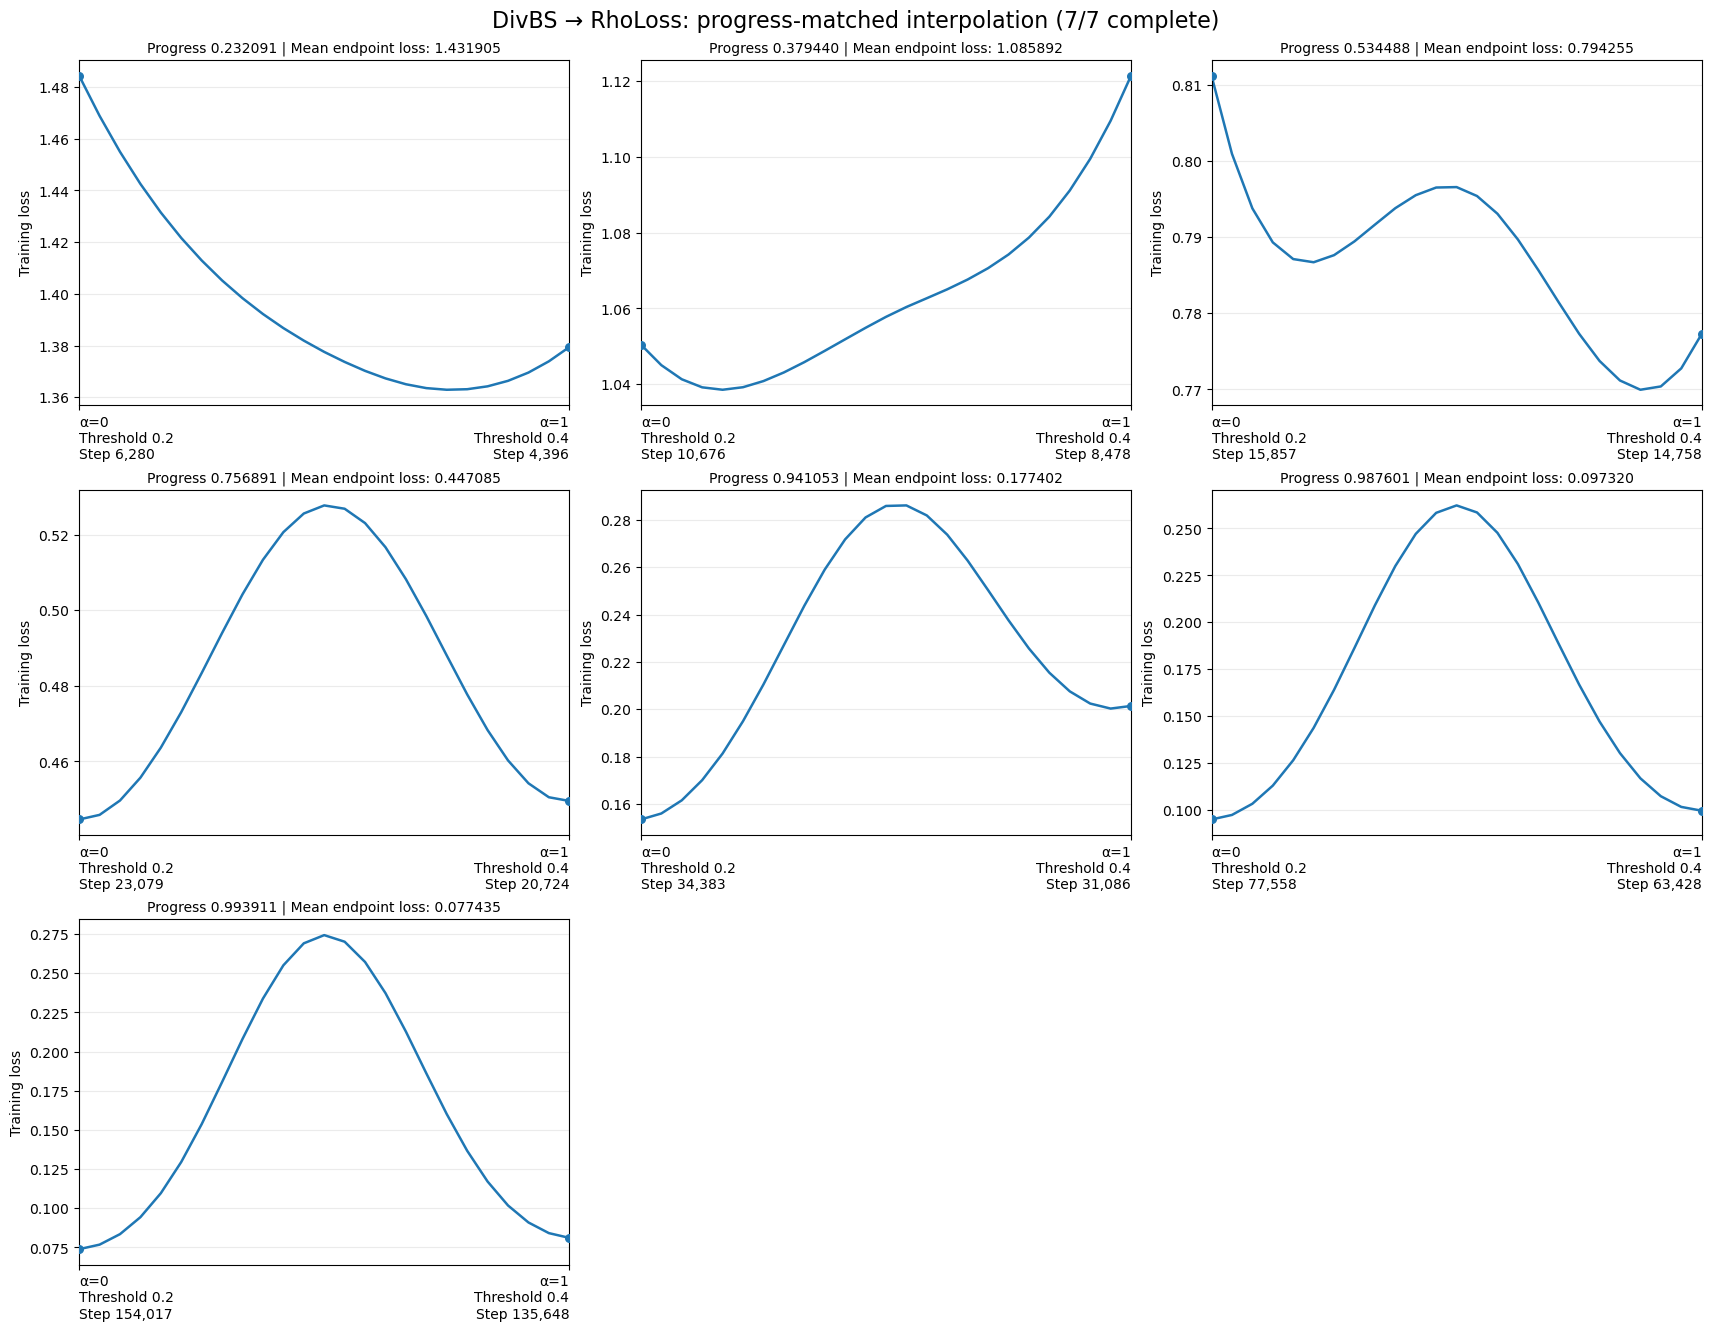

In [3]:
# Current progress-matched jobs from run/interpolation.py.
# Run this cell on its own; rerun as GPU jobs finish writing their .npy files.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

cwd = Path.cwd()
repo_root = next(p for p in [cwd, *cwd.parents] if (p / "REPO_GUIDE.md").is_file())
progress_data_dir = repo_root / "interpolation" / "9-23-26" / "data"
threshold1, threshold2 = 0.2, 0.4
# (model 2 step, model 1 step, matched progress)
progress_jobs = [
    (8478, 10676, 0.379440),
    (4396, 6280, 0.232091),
    (14758, 15857, 0.534488),
    (20724, 23079, 0.756891),
    (31086, 34383, 0.941053),
    (63428, 77558, 0.987601),
    (135648, 154017, 0.993911),
]
progress_jobs = sorted(progress_jobs, key=lambda job: job[2])
columns = 3
rows = (len(progress_jobs) + columns - 1) // columns
progress_fig, progress_axes = plt.subplots(
    rows, columns, figsize=(17, 4.4 * rows), squeeze=False,
    constrained_layout=True,
)
loaded_count = 0
for ax, (step2, step1, progress) in zip(progress_axes.flat, progress_jobs):
    # Match the launcher's epoch checkpoint conversion and output filenames.
    step1, step2 = (step1 // 157) * 157, (step2 // 157) * 157
    data_path = progress_data_dir / (
        f"Train_DivBS-RhoLos_thr-{threshold1}-{threshold2}"
        f"_progress-{progress}_step-{step1}-{step2}.npy"
    )
    # Saved t runs from model 2 to model 1. Display alpha = 1 - t,
    # so LEFT is model 1 (0.2) and RIGHT is model 2 (0.4).
    ax.set_xlim(0, 1)
    ax.set_xticks([0, 1])
    ax.set_xticklabels([
        f"α=0\nThreshold {threshold1:g}\nStep {step1:,}",
        f"α=1\nThreshold {threshold2:g}\nStep {step2:,}",
    ])
    # Keep multiline endpoint labels inside each panel.
    ax.get_xticklabels()[0].set_horizontalalignment("left")
    ax.get_xticklabels()[1].set_horizontalalignment("right")
    ax.set_ylabel("Training loss")
    ax.grid(alpha=0.25)
    ax.set_title(f"Progress {progress:.6f} | Mean endpoint loss: pending", fontsize=10)
    if not data_path.is_file():
        ax.text(0.5, 0.5, "Waiting for GPU output", transform=ax.transAxes,
                ha="center", va="center")
        continue
    try:
        curve = np.load(data_path, allow_pickle=False)
        if curve.ndim != 1 or len(curve) < 2 or not np.isfinite(curve).all():
            raise ValueError("Expected a finite 1D loss array with at least two points")
    except (OSError, ValueError, EOFError) as error:
        ax.text(0.5, 0.5, "Output not readable yet; see message below", transform=ax.transAxes,
                ha="center", va="center", wrap=True)
        print(f"{data_path.name}: {error}")
        continue
    curve = curve[::-1]  # Reverse losses together with endpoint labels.
    t_values = np.linspace(0, 1, len(curve))
    endpoint_mean = float((curve[0] + curve[-1]) / 2)
    ax.plot(t_values, curve, color="C0", linewidth=1.8)
    ax.scatter([0, 1], [curve[0], curve[-1]], color="C0", s=30, zorder=3)
    ax.set_title(
        f"Progress {progress:.6f} | Mean endpoint loss: {endpoint_mean:.6f}",
        fontsize=10,
    )
    loaded_count += 1

for ax in list(progress_axes.flat)[len(progress_jobs):]:
    ax.set_visible(False)
progress_fig.suptitle(
    f"DivBS → RhoLoss: progress-matched interpolation ({loaded_count}/{len(progress_jobs)} complete)",
    fontsize=16,
)
plt.show()
